# 04 · Segmentos de originación y avance por MOB

## Decisión y estado
¿Cómo describir tipo de persona, estrategia, score y ubicación al originar, y cómo medir los avances disponibles en MOB 1, 2 y 3? Este notebook construye una tabla auditable para cruces posteriores con cohortes maduras. Las plantillas son vacías: no hay resultados ni asociaciones reales publicados.

## Tres momentos distintos
1. **Originación (T0):** persona, estrategia, ubicación y score disponibles hasta la fecha de desembolso.
2. **Seguimiento (MOB 1 o 2):** avances ocurridos y disponibles hasta el corte elegido, si existe cobertura suficiente.
3. **Evaluación (MOB 3):** avance hasta MOB 3 y resultado EVER posterior; el comportamiento futuro no es predictor al originar.

La información tardía no se usa como si estuviera disponible antes. Un avance no demuestra estrés financiero, fraude ni causalidad.

## Definiciones
Para cuenta $i$, el MOB calendario del evento $d$ respecto de su fecha de desembolso $o_i$ es:
$$MOB_{i,d}=12(\operatorname{año}(d)-\operatorname{año}(o_i))+\operatorname{mes}(d)-\operatorname{mes}(o_i).$$
Se excluyen eventos anteriores al desembolso. Para horizonte $h$, el monto es $A_i(h)=\sum_{e:\,1\le MOB_e\le h}m_e$ solo para eventos con estado aprobado por negocio y fecha de disponibilidad no posterior al corte de evaluación. Esta convención usa meses calendario; si la institución utiliza ciclos de facturación debe reemplazarse. 

## 1. Preparación
Se requiere un identificador `id_credito` globalmente único en originación, porque la plantilla de avances no contiene `id_comercio`. Ante ambigüedad se detiene el análisis. Fechas y códigos de estado deben verificarse con el proveedor.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(10,5),'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BASE=Path.cwd()
if not (BASE/'plantilla_panel_mensual.csv').is_file():
    BASE=next((p/'03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab' for p in [BASE,*BASE.parents] if (p/'03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab/plantilla_panel_mensual.csv').is_file()),None)
if BASE is None: raise FileNotFoundError('Abra el notebook en el repositorio o junto a las plantillas')
def leer(nombre):
    frame=pd.read_csv(BASE/nombre,encoding='utf-8-sig'); print(f'{nombre}: {len(frame):,} filas'); return frame

FECHA_ASOF=None  # Instante exacto; fecha sola se interpreta a medianoche. Ejemplo: '2026-06-30 23:59:59'
ESTADOS_AVANCE_VALIDOS=set()  # Establezca valores confirmados, p. ej. {'EXITOSO'} solo si el contrato lo garantiza
COBERTURA_AVANCES_CONFIRMADA=False  # No convertir ausencia de registro en ausencia de avance sin confirmación
origin=leer('plantilla_creditos_originacion.csv')
avances=leer('plantilla_avances_tarjeta.csv')
buro=leer('plantilla_buro.csv')
clientes=leer('plantilla_clientes.csv')


plantilla_creditos_originacion.csv: 0 filas
plantilla_avances_tarjeta.csv: 0 filas
plantilla_buro.csv: 0 filas
plantilla_clientes.csv: 0 filas


## 2. Originación: contrato y selección point-in-time
Para cada cuenta se conserva la última consulta de buró con fecha de consulta y disponibilidad ≤ desembolso. La ubicación y tipo de persona se toman de la última referencia de cliente disponible a T0. Empates de fecha se rechazan para no elegir de forma arbitraria. Los campos de origen con disponibilidad posterior a T0 no se tratan como predictores de originación.

In [2]:
def preparar_originacion(origin,buro,clientes,fecha_asof):
    if fecha_asof is None: raise ValueError('Defina FECHA_ASOF')
    o=origin.copy();required=['id_credito','id_cliente','fecha_desembolso','fecha_disponibilidad','estrategia_originacion']
    if set(required)-set(o): raise ValueError('Faltan campos de originación')
    for col in ['fecha_desembolso','fecha_disponibilidad']:o[col]=pd.to_datetime(o[col],errors='coerce')
    if o[['id_credito','id_cliente','fecha_desembolso','fecha_disponibilidad']].isna().any().any():raise ValueError('Originación con identificadores o fechas incompletos')
    if o.id_credito.duplicated().any():raise ValueError('id_credito no es único; la tabla de avances no permite resolver id_comercio')
    asof=pd.Timestamp(fecha_asof);o=o[(o.fecha_desembolso<=asof)&(o.fecha_disponibilidad<=asof)].copy()
    o['datos_originacion_pit']=o.fecha_disponibilidad.le(o.fecha_desembolso)
    o.loc[~o.datos_originacion_pit,'estrategia_originacion']=pd.NA
    out=o[['id_credito','id_cliente','fecha_desembolso','datos_originacion_pit','estrategia_originacion']].copy()
    if not buro.empty:
        b=buro.copy()
        for c in ['fecha_consulta','fecha_disponibilidad']:b[c]=pd.to_datetime(b[c],errors='coerce')
        if b[['id_credito','id_cliente','fecha_consulta','fecha_disponibilidad']].isna().any().any():raise ValueError('Buró con claves o fechas incompletas')
        if b.duplicated(['id_credito','id_cliente','fecha_consulta','fecha_disponibilidad']).any():raise ValueError('Empate de consulta de buró; requiere criterio de versión')
        z=out[['id_credito','id_cliente','fecha_desembolso']].merge(b,on=['id_credito','id_cliente'],how='left',validate='one_to_many')
        z=z[z.fecha_consulta.le(z.fecha_desembolso)&z.fecha_disponibilidad.le(z.fecha_desembolso)].sort_values(['id_credito','fecha_consulta','fecha_disponibilidad'])
        latest=z.drop_duplicates('id_credito',keep='last')[['id_credito','score_buro','fecha_consulta','fecha_disponibilidad']].rename(columns={'fecha_consulta':'fecha_score','fecha_disponibilidad':'fecha_disponibilidad_score'})
        out=out.merge(latest,on='id_credito',how='left',validate='one_to_one')
    if not clientes.empty:
        c=clientes.copy()
        for col in ['fecha_referencia','fecha_disponibilidad']:c[col]=pd.to_datetime(c[col],errors='coerce')
        if c[['id_cliente','fecha_referencia','fecha_disponibilidad']].isna().any().any():raise ValueError('Clientes con claves o fechas incompletas')
        if c.duplicated(['id_cliente','fecha_referencia','fecha_disponibilidad']).any():raise ValueError('Empate en snapshot de cliente')
        z=out[['id_credito','id_cliente','fecha_desembolso']].merge(c,on='id_cliente',how='left',validate='many_to_many')
        z=z[z.fecha_referencia.le(z.fecha_desembolso)&z.fecha_disponibilidad.le(z.fecha_desembolso)].sort_values(['id_credito','fecha_referencia','fecha_disponibilidad'])
        cols=['id_credito','tipo_persona','municipio_dane','departamento_dane'];out=out.merge(z.drop_duplicates('id_credito',keep='last')[cols],on='id_credito',how='left',validate='one_to_one')
    return out
if origin.empty: perfiles=pd.DataFrame();print('PENDIENTE: sin cuentas de originación no hay segmentos observados.')
elif FECHA_ASOF is None: perfiles=pd.DataFrame();print('PENDIENTE: defina FECHA_ASOF.')
else:
    perfiles=preparar_originacion(origin,buro,clientes,FECHA_ASOF)
    print('Cuentas:',len(perfiles),'| originación no disponible a T0:',int((~perfiles.datos_originacion_pit).sum()))
    display(perfiles.head())


PENDIENTE: sin cuentas de originación no hay segmentos observados.


## 3. Avances: primer MOB, monto y disponibilidad
Una misma cuenta puede tener múltiples avances. Se seleccionan únicamente eventos con estado definido por negocio, ocurridos desde el desembolso y disponibles a la fecha de evaluación. Sin acuerdo de estados no se calcula el indicador. Una fecha as-of posterior a MOB 3 no convierte el dato en predictor de T0.

Cuando el corte no alcanza el fin del tercer mes calendario, la ventana está inmadura. Aun con cobertura confirmada, “no” significa ausencia de avance observado **hasta el corte**, no ausencia durante todo MOB 3.

El monto es la suma de eventos disponibles; sin cobertura confirmada no puede afirmarse que sea el total real. La fecha as-of es un instante exacto: una fecha sin hora representa medianoche, no el final del día.

In [3]:
def resumir_avances(perfiles,avances,fecha_asof,estados_validos,cobertura_confirmada=False):
    if not estados_validos:raise ValueError('Defina estados de avance válidos confirmados por negocio')
    if fecha_asof is None:raise ValueError('Defina fecha as-of')
    a=avances.copy();required=['id_avance','id_credito','id_cliente','fecha_avance','fecha_disponibilidad','monto_avance_cop','estado']
    if set(required)-set(a):raise ValueError('Faltan campos de avances')
    if a.empty:
        out=perfiles[['id_credito']].copy();out['primer_mob_avance']=pd.NA;out['monto_avance_mob1_3']=0.0 if cobertura_confirmada else np.nan
        out['avance_mob1_3']='no_hasta_asof' if cobertura_confirmada else 'sin_registro_cobertura_no_confirmada';out['ventana_mob3_cerrada']=((perfiles.fecha_desembolso.dt.to_period('M')+3).dt.to_timestamp('M')<=pd.Timestamp(fecha_asof)).to_numpy();return out,{'eventos_fuera_de_rango_o_no_disponibles':0}
    if a.id_avance.isna().any() or a.id_avance.duplicated().any():raise ValueError('id_avance nulo o duplicado')
    for c in ['fecha_avance','fecha_disponibilidad']:a[c]=pd.to_datetime(a[c],errors='coerce')
    a['monto_avance_cop']=pd.to_numeric(a.monto_avance_cop,errors='coerce')
    if a[['id_credito','id_cliente','fecha_avance','fecha_disponibilidad','monto_avance_cop','estado']].isna().any().any():raise ValueError('Avances con campos obligatorios faltantes')
    if (a.monto_avance_cop<0).any():raise ValueError('Montos negativos requieren política de reversos')
    if (a.fecha_disponibilidad<a.fecha_avance).any():raise ValueError('Disponibilidad anterior al evento: revisar fuente')
    a=a[a.estado.isin(estados_validos)].copy()
    a=a.merge(perfiles[['id_credito','id_cliente','fecha_desembolso']],on=['id_credito','id_cliente'],how='left',validate='many_to_one',indicator=True)
    if a._merge.ne('both').any():raise ValueError('Eventos sin correspondencia exacta de cuenta y cliente')
    if (a.fecha_avance<a.fecha_desembolso).any():raise ValueError('Avance anterior al desembolso')
    a['mob_avance']=12*(a.fecha_avance.dt.year-a.fecha_desembolso.dt.year)+(a.fecha_avance.dt.month-a.fecha_desembolso.dt.month)
    ok=a.mob_avance.between(1,3)&a.fecha_avance.le(pd.Timestamp(fecha_asof))&a.fecha_disponibilidad.le(pd.Timestamp(fecha_asof))
    rec=a[ok].groupby('id_credito',as_index=False).agg(primer_mob_avance=('mob_avance','min'),monto_avance_mob1_3=('monto_avance_cop','sum'),numero_avances_mob1_3=('id_avance','size'))
    out=perfiles[['id_credito']].merge(rec,on='id_credito',how='left',validate='one_to_one');observado=out.numero_avances_mob1_3.notna()
    out['avance_mob1_3']=np.where(observado,'sí','no_hasta_asof' if cobertura_confirmada else 'sin_registro_cobertura_no_confirmada')
    cierre=(perfiles.fecha_desembolso.dt.to_period('M')+3).dt.to_timestamp('M')
    out['ventana_mob3_cerrada']=(cierre<=pd.Timestamp(fecha_asof)).to_numpy()
    if cobertura_confirmada:out[['monto_avance_mob1_3','numero_avances_mob1_3']]=out[['monto_avance_mob1_3','numero_avances_mob1_3']].fillna(0)
    return out,{'eventos_fuera_de_rango_o_no_disponibles':int((~ok).sum())}
if perfiles.empty: resumen=pd.DataFrame();print('PENDIENTE: se necesitan cuentas y una fecha de evaluación.')
elif not ESTADOS_AVANCE_VALIDOS: resumen=pd.DataFrame();print('PENDIENTE: confirmar y configurar estados de avance.')
else:
    resumen,diagnostico=resumir_avances(perfiles,avances,FECHA_ASOF,ESTADOS_AVANCE_VALIDOS,COBERTURA_AVANCES_CONFIRMADA)
    display(pd.Series(diagnostico).to_frame('conteo'));display(resumen.head())


PENDIENTE: se necesitan cuentas y una fecha de evaluación.


## 3b. Variables disponibles al cierre de un MOB por cuenta
Para analizar un pronóstico al finalizar MOB 1, 2 o 3 se calcula un corte individual por cuenta, no solo una fecha común para toda la cartera. Se requiere que el cierre del horizonte haya ocurrido antes de `FECHA_ASOF`; se usan únicamente avances ocurridos y publicados hasta ese cierre. El calendario es por mes civil y supone que `fecha_disponibilidad` y el corte se expresan en la misma zona horaria.

Una cuenta aún inmadura recibe valores faltantes. La ausencia de registro solo se interpreta como ausencia de avance cuando se haya confirmado la cobertura del origen.

In [4]:
def avances_a_cierre_mob(perfiles,avances,fecha_asof,h,estados_validos,cobertura_confirmada=False):
    if fecha_asof is None or h not in (1,2,3):raise ValueError('Defina fecha_asof y horizonte h en {1,2,3}')
    if not estados_validos:raise ValueError('Defina estados válidos')
    if perfiles.id_credito.duplicated().any():raise ValueError('id_credito no es único')
    asof=pd.Timestamp(fecha_asof);p=perfiles[['id_credito','id_cliente','fecha_desembolso']].copy()
    if p[['id_credito','id_cliente','fecha_desembolso']].isna().any().any():raise ValueError('Faltan claves o fecha de desembolso')
    p['cierre_h']=(p.fecha_desembolso.dt.to_period('M')+h).dt.to_timestamp('M')+pd.Timedelta(days=1)-pd.Timedelta(nanoseconds=1)
    p['maduro_h']=p.cierre_h.le(asof)
    a=avances.copy();required=['id_avance','id_credito','id_cliente','fecha_avance','fecha_disponibilidad','monto_avance_cop','estado']
    if set(required)-set(a):raise ValueError('Faltan campos de avances')
    if a.id_avance.isna().any() or a.id_avance.duplicated().any():raise ValueError('id_avance nulo o duplicado')
    for col in ['fecha_avance','fecha_disponibilidad']:a[col]=pd.to_datetime(a[col],errors='coerce')
    a['monto_avance_cop']=pd.to_numeric(a.monto_avance_cop,errors='coerce')
    if not a.empty and a[required].isna().any().any():raise ValueError('Datos de avances incompletos')
    if (a.monto_avance_cop<0).any() or (a.fecha_disponibilidad<a.fecha_avance).any():raise ValueError('Monto negativo o disponibilidad anterior al evento')
    a=a[a.estado.isin(estados_validos)].merge(p,on=['id_credito','id_cliente'],how='left',validate='many_to_one',indicator=True)
    if a._merge.ne('both').any():raise ValueError('Avance sin correspondencia en perfiles')
    if (a.fecha_avance<a.fecha_desembolso).any():raise ValueError('Avance anterior al desembolso')
    mob=12*(a.fecha_avance.dt.year-a.fecha_desembolso.dt.year)+(a.fecha_avance.dt.month-a.fecha_desembolso.dt.month)
    usable=a.maduro_h&mob.between(1,h)&a.fecha_avance.le(a.cierre_h)&a.fecha_disponibilidad.le(a.cierre_h)
    x=a.loc[usable].copy();x['mob_avance']=mob[usable]
    agg=x.groupby('id_credito',as_index=False).agg(primer_mob=('mob_avance','min'),monto_disponible=('monto_avance_cop','sum'),eventos_disponibles=('id_avance','size'))
    out=p.merge(agg,on='id_credito',how='left',validate='one_to_one');tiene=out.eventos_disponibles.notna()
    out['estado_avance']=np.where(~out.maduro_h,'inmaduro',np.where(tiene,'sí','no_hasta_cierre' if cobertura_confirmada else 'sin_registro_cobertura_no_confirmada'))
    if cobertura_confirmada:
        m=out.maduro_h&~tiene;out.loc[m,['monto_disponible','eventos_disponibles']]=0
    return out
HORIZONTE_MOB=1  # Momento de evaluación: 1, 2 o 3; no usar MOB 3 para predecir desde originación.
if not perfiles.empty and ESTADOS_AVANCE_VALIDOS and FECHA_ASOF:
    avance_pit=avances_a_cierre_mob(perfiles,avances,FECHA_ASOF,HORIZONTE_MOB,ESTADOS_AVANCE_VALIDOS,COBERTURA_AVANCES_CONFIRMADA)
    display(avance_pit.head())
else:print('PENDIENTE: configurar datos, fecha y estados válidos para evaluar el horizonte.')

PENDIENTE: configurar datos, fecha y estados válidos para evaluar el horizonte.


## 4. Perfiles descriptivos y visualización
Los conteos describen registros disponibles y no una tasa de mora. La relación con EVER >30 exige una tabla de resultados maduros con la misma definición de cuenta, cohorte y fecha de observación. Los grupos pequeños deben suprimirse o agregarse conforme a la política de privacidad.

In [5]:
if not resumen.empty:
    counts=resumen.primer_mob_avance.value_counts().reindex([1,2,3],fill_value=0)
    fig,ax=plt.subplots(figsize=(8,4));ax.bar(['MOB 1','MOB 2','MOB 3'],counts,color='#25658c');ax.set(title='Primer avance registrado por mes de vida',xlabel='Mes de vida',ylabel='Cuentas con avance observado');ax.bar_label(ax.containers[0]);fig.tight_layout();plt.show()
    print('Sin registro no confirma no-avance:',int(resumen.avance_mob1_3.eq('sin_registro_cobertura_no_confirmada').sum()))
else: print('Gráfico pendiente de cuentas, fechas y estados de avance confirmados.')


Gráfico pendiente de cuentas, fechas y estados de avance confirmados.


## Interpretación y siguiente paso
El score de buró requiere bandas y versión de proveedor acordadas; ubicación exige códigos DANE y vigencia confirmados. Los cruces por estrategia, tipo y región solo son válidos tras controlar completitud, maduración, temporalidad y tamaño de muestra. No se calculan probabilidades de fraude ni se dan etiquetas conductuales a los clientes. El notebook 02 define EVER y sus denominadores; los modelos que empleen avances deben usar solo información conocida al momento del pronóstico.

## Demostración visual aislada: datos simulados

Ejemplo inventado y reproducible con semilla fija. No representa clientes, saldos, frecuencia de avances ni riesgo de una cartera. No se mezcla con los análisis de plantillas reales.

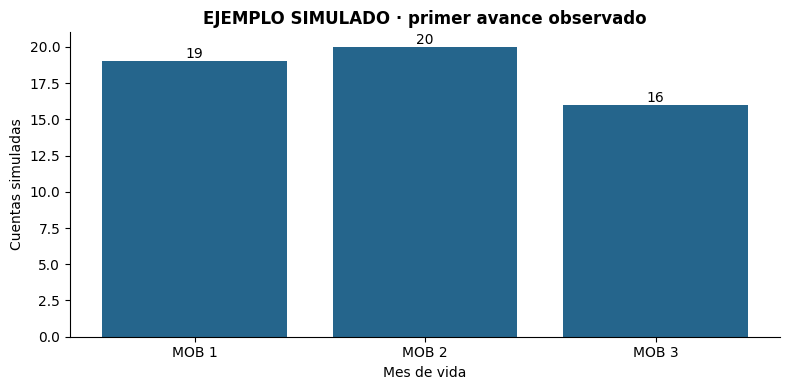

Datos simulados; cuentas: 100 | con avance: 55


In [6]:
rng=np.random.default_rng(20261112)
o_demo=pd.DataFrame({'id_credito':[f'SIM-{i:03d}' for i in range(100)],'id_cliente':[f'C-SIM-{i:03d}' for i in range(100)],'fecha_desembolso':['2024-01-05']*100,'fecha_disponibilidad':['2024-01-05']*100,'estrategia_originacion':['DEMO']*100})
perfiles_demo=preparar_originacion(o_demo,pd.DataFrame(),pd.DataFrame(),'2024-05-01')
registros=[]
for i in range(100):
    if rng.random()<.48:
        mob=int(rng.integers(1,4));dia=pd.Timestamp('2024-01-05')+pd.DateOffset(months=mob)
        registros.append({'id_avance':f'SIM-E-{i:03d}','id_credito':f'SIM-{i:03d}','id_cliente':f'C-SIM-{i:03d}','fecha_avance':dia,'fecha_disponibilidad':dia,'monto_avance_cop':float(rng.integers(10000,100000)),'estado':'EXITO_DEMO'})
avances_demo=pd.DataFrame(registros);res_demo,_=resumir_avances(perfiles_demo,avances_demo,'2024-05-01',{'EXITO_DEMO'},True)
counts=res_demo.primer_mob_avance.value_counts().reindex([1,2,3],fill_value=0)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(['MOB 1','MOB 2','MOB 3'],counts,color='#25658c');ax.set(title='EJEMPLO SIMULADO · primer avance observado',xlabel='Mes de vida',ylabel='Cuentas simuladas');ax.bar_label(ax.containers[0]);fig.tight_layout();plt.show()
print('Datos simulados; cuentas:',len(perfiles_demo),'| con avance:',int(res_demo.avance_mob1_3.eq('sí').sum()))